
# EMG Signal Detective
### Exploring Surface EMG Signals with Python

## 1. Introduction

This project explores surface electromyography (sEMG) signals using Python and a real-world dataset from PhysioNet.

The analysis focuses on a 2-second recording of the left tibialis anterior muscle during walking. The goal is to understand the signal's characteristics and explore how basic signal processing affects it.

### Objectives

- Visualize and examine the EMG signal.
- Analyze its amplitude and frequency characteristics using MAV, RMS, and Fourier analysis.
- Apply a moving average filter and compare the original and processed signals.


## 2. Setup and Data Loading

The EMG recording is obtained from PhysioNet using the WFDB library. NumPy and Matplotlib are used for numerical analysis and visualization.

The first 2 seconds of recording S01 are loaded for this investigation.

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import wfdb
from pathlib import Path
figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)


In [2]:

record = wfdb.rdrecord(
    "S01",
    pn_dir="semg/1.0.1",
    sampfrom=0,
    sampto=4000
)

print("Sampling rate:", record.fs, "Hz")
print("Data shape:", record.p_signal.shape)
print("Available channels:", record.sig_name)


Sampling rate: 2000 Hz
Data shape: (4000, 14)
Available channels: ['baso LT FOOT', 'gonio RT HIP', 'semg LT TIB.A', 'semg LT LAT.G', 'semg LT REC.F', 'semg LT HAM', 'semg LT LAT.V', 'baso RT FOOT', 'gonio RT KNEE', 'semg RT TIB.A', 'semg RT LAT.G', 'semg RT REC.F', 'semg RT HAM', 'semg RT LAT.V']


In [3]:

channel_name = "semg LT TIB.A"
channel_index = record.sig_name.index(channel_name)

emg = record.p_signal[:, channel_index]

time = np.arange(len(emg)) / record.fs

print("Selected channel:", channel_name)
print("Number of samples:", len(emg))
print("Segment duration:", len(emg) / record.fs, "seconds")


Selected channel: semg LT TIB.A
Number of samples: 4000
Segment duration: 2.0 seconds



### Observation

Recording S01 contains 14 channels sampled at 2,000 Hz. The selected channel, `semg LT TIB.A`, represents surface EMG activity from the left tibialis anterior muscle.

The selected segment contains 4,000 samples, corresponding to the first 2 seconds of recording.



## 3. Understanding the Signal

Before analyzing the EMG waveform, it is important to understand its basic properties.

The recording has a sampling rate of 2,000 Hz, meaning that 2,000 measurements are collected every second. The signal's amplitude is expressed in microvolts (μV), as specified in the dataset documentation.


In [4]:

sampling_interval = 1 / record.fs

print("Sampling rate:", record.fs, "samples/second")
print("Sampling interval:", sampling_interval, "seconds")
print("First five time values:", time[:5])

print("Minimum amplitude:", np.min(emg), "μV")
print("Maximum amplitude:", np.max(emg), "μV")


Sampling rate: 2000 samples/second
Sampling interval: 0.0005 seconds
First five time values: [0.     0.0005 0.001  0.0015 0.002 ]
Minimum amplitude: -13.991963483269073 μV
Maximum amplitude: 17.99562516551596 μV



### Observation

The selected EMG recording contains 2,000 samples per second, with a time interval of 0.0005 seconds between consecutive samples. The signal amplitude is measured in microvolts (μV).

The first 2 seconds of the recording contain 4,000 samples.



## 4. Signal Visualization

Visualizing the EMG signal helps examine its amplitude variations and identify notable features over time.

The full recording is plotted first, followed by a closer view of a shorter segment. The largest positive peak is also identified and annotated.


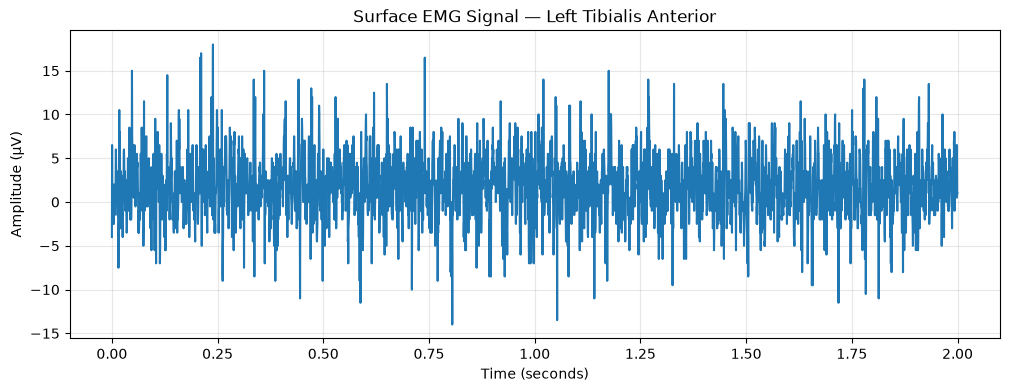

In [5]:

plt.figure(figsize=(12, 4))

plt.plot(time, emg)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (μV)")
plt.title("Surface EMG Signal — Left Tibialis Anterior")
plt.grid(alpha=0.3)

plt.savefig("../figures/01_signal_overview.png",
            dpi=300, bbox_inches="tight")
plt.show()


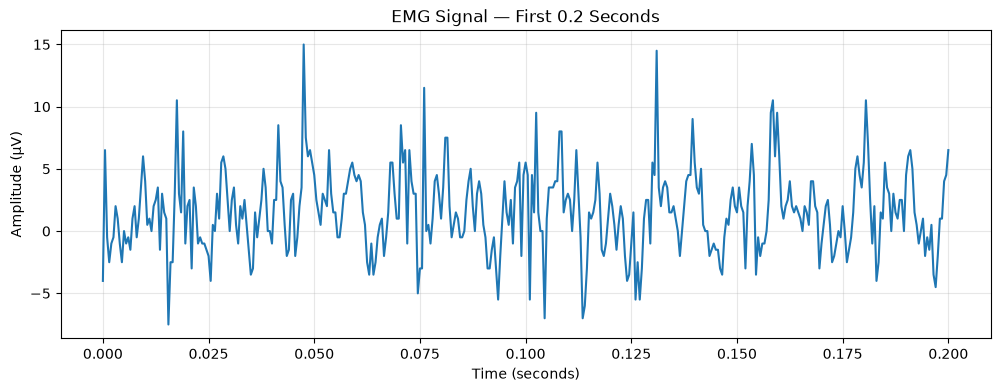

In [6]:

zoom = time <= 0.2

plt.figure(figsize=(12, 4))

plt.plot(time[zoom], emg[zoom])

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (μV)")
plt.title("EMG Signal — First 0.2 Seconds")
plt.grid(alpha=0.3)

plt.savefig("../figures/02_signal_zoom.png",
            dpi=300, bbox_inches="tight")
plt.show()


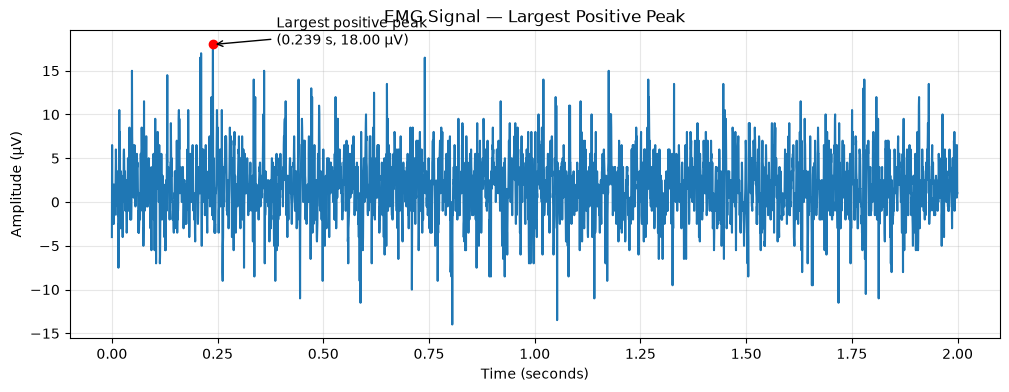

Peak time: 0.239 seconds
Peak amplitude: 17.99562516551596 μV


In [7]:

peak_index = np.argmax(emg)

peak_time = time[peak_index]
peak_amplitude = emg[peak_index]

plt.figure(figsize=(12, 4))

plt.plot(time, emg)
plt.scatter(peak_time, peak_amplitude, color="red", zorder=3)

plt.annotate(
    f"Largest positive peak\n({peak_time:.3f} s, {peak_amplitude:.2f} μV)",
    xy=(peak_time, peak_amplitude),
    xytext=(peak_time + 0.15, peak_amplitude),
    arrowprops=dict(arrowstyle="->")
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (μV)")
plt.title("EMG Signal — Largest Positive Peak")
plt.grid(alpha=0.3)

plt.savefig("../figures/03_annotated_peak.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Peak time:", peak_time, "seconds")
print("Peak amplitude:", peak_amplitude, "μV")



### Observations

The EMG signal fluctuates around zero throughout the recording, with variations in amplitude and occasional larger excursions.

The largest positive peak occurs at approximately 0.239 seconds, reaching an amplitude of 18.00 μV.

The zoomed view provides a clearer look at the rapid fluctuations within a shorter time interval.



## 5. Amplitude Analysis

Mean Absolute Value (MAV) and Root Mean Square (RMS) are used to quantify the amplitude of the EMG signal.

MAV measures the average absolute amplitude, while RMS provides a measure that gives greater weight to larger signal values.


In [8]:

mav = np.mean(np.abs(emg))

rms = np.sqrt(np.mean(emg ** 2))

print(f"Mean Absolute Value (MAV): {mav:.4f} μV")
print(f"Root Mean Square (RMS): {rms:.4f} μV")


Mean Absolute Value (MAV): 2.9799 μV
Root Mean Square (RMS): 3.8392 μV



### Observations

The calculated MAV is approximately 2.98 μV, while the RMS is approximately 3.84 μV.

Both measurements describe the amplitude characteristics of the selected EMG segment. RMS is higher than MAV because it gives greater weight to samples with larger amplitudes.

These values provide a quantitative reference for comparing the original signal with the processed signal later in the analysis.



## 6. Frequency Analysis

Frequency analysis helps examine the different frequency components that make up the EMG signal.

The Fast Fourier Transform (FFT) is used to convert the signal from the time domain into the frequency domain.

The signal is mean-centered before analysis to remove its constant average offset, making the frequency components easier to examine.


In [9]:

# Remove the signal's average value
emg_centered = emg - np.mean(emg)

# Calculate the frequency spectrum
spectrum = np.fft.rfft(emg_centered)

# Create the corresponding frequency axis
frequencies = np.fft.rfftfreq(
    len(emg_centered),
    d=1 / record.fs
)

# Calculate the magnitude of each frequency component
magnitude = np.abs(spectrum)

print("Frequency resolution:",
      frequencies[1] - frequencies[0], "Hz")


Frequency resolution: 0.5 Hz


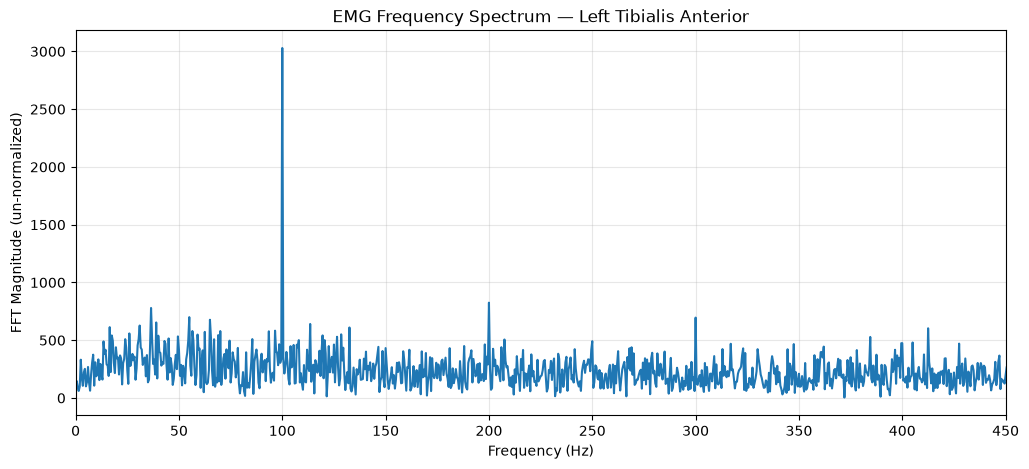

In [10]:

plt.figure(figsize=(12, 5))

plt.plot(frequencies, magnitude)

plt.xlim(0, 450)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT Magnitude (un-normalized)")
plt.title("EMG Frequency Spectrum — Left Tibialis Anterior")
plt.grid(alpha=0.3)

plt.savefig("../figures/04_frequency_spectrum.png",
            dpi=300, bbox_inches="tight")
plt.show()



### Observations

The frequency spectrum displays the distribution of frequency components within the selected EMG segment.

A prominent component appears around 100 Hz, alongside smaller components across the analyzed frequency range.

The original spectrum also contained a large component at 0 Hz, which was removed through mean-centering before plotting.

The frequency spectrum helps identify prominent components, although their individual sources cannot be determined from this plot alone.



## 7. Signal Processing

A moving average filter is applied to the EMG signal to reduce rapid fluctuations and produce a smoother waveform.

A window of 10 samples is used to calculate the average of neighbouring samples as the window moves across the signal.


In [11]:

window_size = 10

moving_average = np.ones(window_size) / window_size

emg_smoothed = np.convolve(
    emg,
    moving_average,
    mode="same"
)

print("Window size:", window_size, "samples")
print("Window duration:", window_size / record.fs, "seconds")


Window size: 10 samples
Window duration: 0.005 seconds


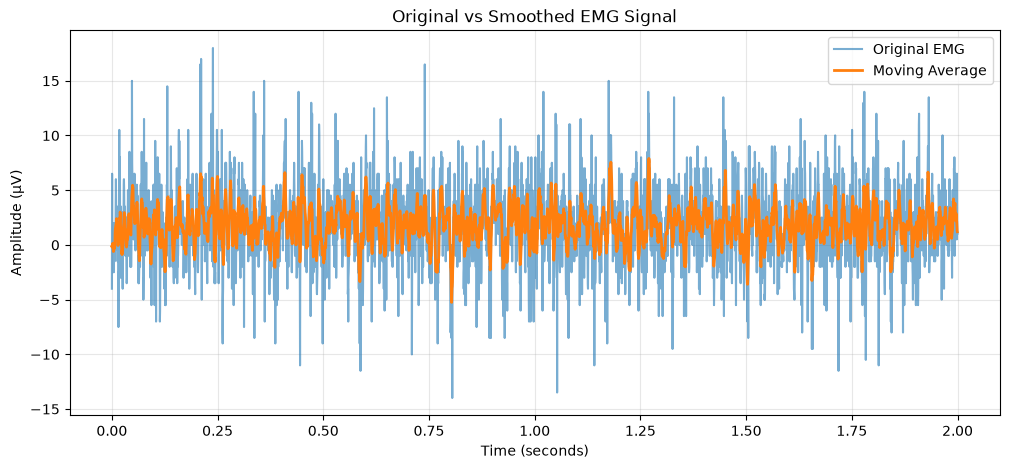

In [12]:

plt.figure(figsize=(12, 5))

plt.plot(time, emg, label="Original EMG", alpha=0.6)
plt.plot(time, emg_smoothed, label="Moving Average", linewidth=2)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (μV)")
plt.title("Original vs Smoothed EMG Signal")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("../figures/05_original_vs_smoothed.png",
            dpi=300, bbox_inches="tight")
plt.show()



### Observations

The moving average produced a smoother waveform while preserving the general shape of the original signal.

Some of the larger fluctuations and peaks were reduced. This demonstrates how averaging neighbouring samples can change the amplitude characteristics of the signal.



## 8. Comparison of Results

The original and processed EMG signals are compared using their amplitude measurements and frequency spectra.

This comparison helps illustrate how the moving average filter changes the characteristics of the signal.


In [13]:

# Calculate measurements for the smoothed signal
mav_smoothed = np.mean(np.abs(emg_smoothed))
rms_smoothed = np.sqrt(np.mean(emg_smoothed ** 2))

# Calculate percentage decreases
mav_decrease = ((mav - mav_smoothed) / mav) * 100
rms_decrease = ((rms - rms_smoothed) / rms) * 100

print("Amplitude Comparison")
print("--------------------")
print(f"Original MAV: {mav:.4f} μV")
print(f"Smoothed MAV: {mav_smoothed:.4f} μV")
print(f"MAV decrease: {mav_decrease:.1f}%")
print()
print(f"Original RMS: {rms:.4f} μV")
print(f"Smoothed RMS: {rms_smoothed:.4f} μV")
print(f"RMS decrease: {rms_decrease:.1f}%")


Amplitude Comparison
--------------------
Original MAV: 2.9799 μV
Smoothed MAV: 2.0496 μV
MAV decrease: 31.2%

Original RMS: 3.8392 μV
Smoothed RMS: 2.4841 μV
RMS decrease: 35.3%


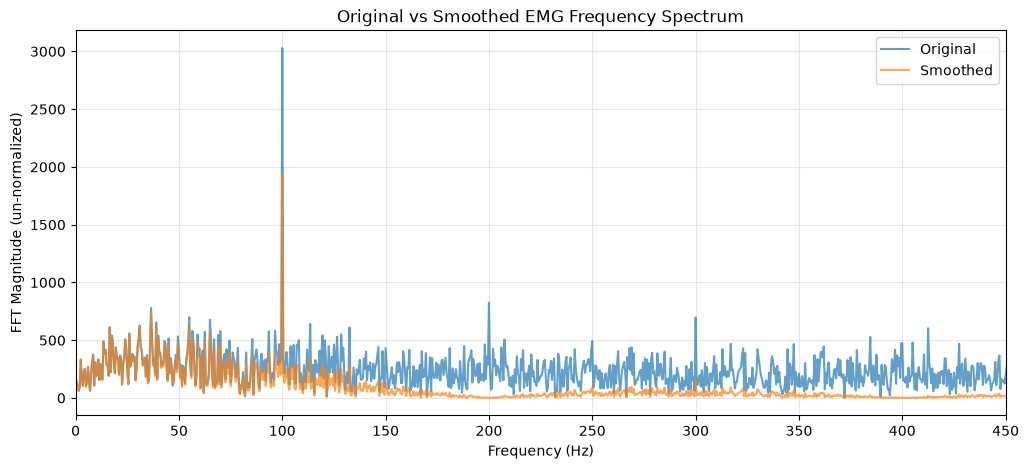

In [14]:

# Mean-center the smoothed signal
emg_smoothed_centered = emg_smoothed - np.mean(emg_smoothed)

# Calculate its frequency spectrum
spectrum_smoothed = np.fft.rfft(emg_smoothed_centered)
magnitude_smoothed = np.abs(spectrum_smoothed)

# Plot both spectra
plt.figure(figsize=(12, 5))

plt.plot(frequencies, magnitude,
         label="Original", alpha=0.7)

plt.plot(frequencies, magnitude_smoothed,
         label="Smoothed", alpha=0.7)

plt.xlim(0, 450)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT Magnitude (un-normalized)")
plt.title("Original vs Smoothed EMG Frequency Spectrum")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("../figures/06_frequency_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()



### Observations

The moving average filter reduced both amplitude measurements. MAV decreased by approximately 31.2%, while RMS decreased by approximately 35.3%.

The frequency spectrum comparison also shows attenuation across much of the analyzed frequency range. The prominent component around 100 Hz remained visible but was reduced.

These results demonstrate that the moving average changes both the amplitude and frequency characteristics of the original EMG signal.



## 9. Interpret Results

### 9.1 Signal Characteristics

The selected EMG recording showed continuous fluctuations in amplitude throughout the analyzed 2-second segment. The original signal had a MAV of 2.9799 μV and an RMS of 3.8392 μV.

Frequency analysis revealed several frequency components, including a prominent component around 100 Hz. However, the source of this component could not be determined from the analysis alone.

### 9.2 Effects of Signal Processing

Applying a 10-sample moving average reduced the MAV to 2.0496 μV and the RMS to 2.4841 μV, representing decreases of approximately 31.2% and 35.3%, respectively.

The frequency spectrum also showed attenuation across much of the analyzed frequency range. Although the waveform became smoother, the filter altered both its amplitude and frequency characteristics.

### 9.3 Limitations and Uncertainties

Several limitations should be considered when interpreting these results:

- The analysis focused on a single muscle channel and a short 2-second segment.
- The original dataset signal was already hardware-filtered before analysis.
- The moving average may suppress meaningful muscle activity as well as unwanted fluctuations.
- Results depend on the selected window size.
- A smoother signal does not necessarily mean improved signal quality.
- Potential sources of noise, such as power-line interference, movement artifacts, and electronic noise, were considered but not individually confirmed.

Therefore, the observed changes demonstrate the effects of signal processing, but do not establish that noise was successfully removed or that the processed signal is more accurate.



## 10. Conclusion

This project explored a surface EMG recording using Python, examining its amplitude, frequency characteristics, and response to basic signal processing.

MAV, RMS, and frequency analysis provided different ways to describe the original signal. Applying a moving average demonstrated how processing can reduce fluctuations while also changing meaningful signal characteristics.

Overall, this project provided an introduction to EMG signal analysis and demonstrated the importance of understanding both the signal and the effects of processing before drawing conclusions.
